# Test 0: Pre-reconstruction 2PCF multipoles

## Aim
Measure the pre-reconstruction correlation-function multipoles for 10
independent simulations with the same ΛCDM cosmology. The requested
separation range is 0–200 Mpc/h, with bins of width 5 Mpc/h.

## Catalogue choice
We will start with the standard Quijote `fiducial` simulations
(realizations 0–9). This set has zero neutrino mass and uses 2LPT
initial conditions. We will use the Friends-of-Friends (FoF) halo
catalogue at snapshot 003, corresponding to z = 0.5. Quijote's
standard box is 1000 Mpc/h on each side.

References:
- [Quijote simulation types](https://quijote-simulations.readthedocs.io/en/latest/types.html)
- [Quijote FoF catalogue guide](https://quijote-simulations.readthedocs.io/en/latest/halos.html)

## Step 1: Prepare and locate the catalogue
We created the NERSC scratch destination for realization 0 and checked
for `group_tab_003.*` files. The check found zero files. Therefore,
the catalogue has not yet been transferred; no halo measurement has
been made.

In [3]:
from pathlib import Path
import os

scratch = Path(os.environ["SCRATCH"])
catalogue = scratch / "Quijote/Halos/FoF/fiducial/0/groups_003"
parts = sorted(catalogue.glob("group_tab_003.*"))

print("NERSC scratch:", scratch)
print("First catalogue directory:", catalogue)
print("Catalogue parts found:", len(parts))
for part in parts:
    print(part.name)

NERSC scratch: /pscratch/sd/m/mawais
First catalogue directory: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003
Catalogue parts found: 1
group_tab_003.0


In [4]:
from pathlib import Path

destination = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003")
destination.mkdir(parents=True, exist_ok=True)
print(destination)

/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003


## Step 2: Transfer the first FoF halo catalogue

The destination directory on NERSC is
`/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003/`.

It currently contains no `group_tab_003.*` files. We will transfer
the FoF halo catalogue for fiducial realization 0, snapshot 003
(z = 0.5), before attempting to read or measure it. We will check
one realization first, then extend the procedure to 10.

In [5]:
from pathlib import Path

folder = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003")
parts = sorted(folder.glob("group_tab_003.*"))

print("Catalogue parts found:", len(parts))
for part in parts:
    print(part.name, f"{part.stat().st_size / 1024**2:.2f} MiB")

Catalogue parts found: 1
group_tab_003.0 24.81 MiB


## Step 2: Verify the transferred FoF catalogue

Globus reports that the first catalogue file was transferred successfully.
Here we check that it is present in NERSC scratch before reading any halo data.

In [6]:
from pathlib import Path

folder = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003")
parts = sorted(folder.glob("group_tab_003.*"))

print("Catalogue directory:", folder)
print("Catalogue parts found:", len(parts))

for part in parts:
    print(part.name, part.stat().st_size, "bytes")

Catalogue directory: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003
Catalogue parts found: 1
group_tab_003.0 26018184 bytes


## Step 3: Set up the FoF catalogue reader

The catalogue file is present. This notebook's Python environment could not
previously import `readfof`, so we obtain the reader from the official Pylians3
repository and record which copy we use.

In [7]:
from pathlib import Path
from urllib.request import urlopen
import sys

reader_dir = Path.home() / "quijote_tools"
reader_dir.mkdir(exist_ok=True)
reader_file = reader_dir / "readfof.py"

if not reader_file.exists():
    url = "https://raw.githubusercontent.com/franciscovillaescusa/Pylians3/master/library/readfof.py"
    with urlopen(url, timeout=30) as response:
        reader_file.write_bytes(response.read())

sys.path.insert(0, str(reader_dir))
import readfof

print("FoF reader:", readfof.__file__)

FoF reader: /global/homes/m/mawais/quijote_tools/readfof.py


## Step 4: Read the first halo catalogue

We read realization 0 at snapshot 003. We do not request particle IDs because
this step needs only halo properties. We print the halo count and the ranges of
positions and masses to check that the catalogue was interpreted correctly.

In [8]:
import numpy as np

snapdir = "/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0"

fof = readfof.FoF_catalog(
    snapdir, 3,
    long_ids=False, swap=False, SFR=False, read_IDs=False
)

positions = np.asarray(fof.GroupPos) / 1e3     # Mpc/h
masses = np.asarray(fof.GroupMass) * 1e10       # Msun/h
particles = np.asarray(fof.GroupLen)

print("Total FoF halos:", len(particles))
print("Halos with at least 20 particles:", np.count_nonzero(particles >= 20))
print("Particle count range:", particles.min(), "to", particles.max())
print("Position range [Mpc/h]:", positions.min(), "to", positions.max())
print("Mass range [Msun/h]:", masses.min(), "to", masses.max())

Total FoF halos: 309740
Halos with at least 20 particles: 309740
Particle count range: 20 to 3189
Position range [Mpc/h]: 1.6815186e-05 to 999.99646
Mass range [Msun/h]: 1.3131216e+13 to 2.0937775e+15


## Step 5: Define the halo sample and line of sight

We use the Quijote fiducial realization 0 at z = 0.5 in a periodic
1000 Mpc/h box. For this initial check, we retain all FoF halos
(20 or more particles) and report their number density. We create
a separate redshift-space position array by shifting the z coordinate
with each halo's line-of-sight peculiar velocity; the original
real-space positions remain available for comparison.

The mass selection and line-of-sight convention will be held fixed
for every realization in Test 0.

In [9]:
import numpy as np
from importlib.util import find_spec

boxsize = 1000.0                   # Mpc/h
redshift = 0.5
omega_m = 0.3175                   # Quijote fiducial
omega_lambda = 1.0 - omega_m       # flat, massless-neutrino fiducial model
los_axis = 2                      # z axis

# H(z)/h has units km/s/(Mpc/h).
hubble_over_h = 100.0 * np.sqrt(
    omega_m * (1.0 + redshift)**3 + omega_lambda
)

real_positions = np.asarray(positions, dtype=np.float64)
physical_velocities = np.asarray(fof.GroupVel, dtype=np.float64) * (1.0 + redshift)

redshift_positions = real_positions.copy()
displacement = (
    (1.0 + redshift) * physical_velocities[:, los_axis] / hubble_over_h
)
redshift_positions[:, los_axis] = (
    real_positions[:, los_axis] + displacement
) % boxsize

assert real_positions.shape == physical_velocities.shape
assert np.isfinite(redshift_positions).all()
assert ((redshift_positions >= 0) & (redshift_positions < boxsize)).all()

separation_edges = np.arange(0.0, 205.0, 5.0)  # 40 bins, edges 0 through 200

print("Halos retained:", len(real_positions))
print("Number density [(h/Mpc)^3]:", len(real_positions) / boxsize**3)
print("H(z)/h [km/s/(Mpc/h)]:", hubble_over_h)
print("Line of sight: z axis")
print("Absolute z displacement, median/max [Mpc/h]:",
      np.median(np.abs(displacement)), np.max(np.abs(displacement)))
print("Separation bins:", len(separation_edges) - 1)
print("pycorr available:", find_spec("pycorr") is not None)
print("Corrfunc available:", find_spec("Corrfunc") is not None)

Halos retained: 309740
Number density [(h/Mpc)^3]: 0.00030974
H(z)/h [km/s/(Mpc/h)]: 132.44102461095656
Line of sight: z axis
Absolute z displacement, median/max [Mpc/h]: 2.2781620237531657 23.519658127077907
Separation bins: 40
pycorr available: True
Corrfunc available: True


## Step 6: Measure pre-reconstruction 2PCF multipoles for realization 0

We count halo pairs in redshift space using periodic boundaries and the
z axis as the line of sight. Separation edges run from 0 to 200 Mpc/h
in steps of 5 Mpc/h. We project the result onto multipoles ell = 0, 2, 4.
This is the pre-reconstruction measurement: no reconstruction has been
applied to the halo positions.

In [13]:
from pathlib import Path
import sys
import numpy as np
from pycorr import TwoPointCorrelationFunction

# 1. Load the FoF reader downloaded earlier.
reader_dir = Path.home() / "quijote_tools"
if not (reader_dir / "readfof.py").is_file():
    raise FileNotFoundError(f"FoF reader not found: {reader_dir / 'readfof.py'}")

sys.path.insert(0, str(reader_dir))
import readfof

# 2. Read Quijote fiducial realization 0 at snapshot 003 (z = 0.5).
snapdir = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0")
catalogue_file = snapdir / "groups_003" / "group_tab_003.0"
if not catalogue_file.is_file():
    raise FileNotFoundError(f"Catalogue not found: {catalogue_file}")

fof = readfof.FoF_catalog(
    str(snapdir), 3,
    long_ids=False, swap=False, SFR=False, read_IDs=False
)

# 3. Keep FoF halos with at least 20 particles.
keep = np.asarray(fof.GroupLen) >= 20
positions_real = np.asarray(fof.GroupPos[keep], dtype=np.float64) / 1e3
velocities = np.asarray(fof.GroupVel[keep], dtype=np.float64) * 1.5

# 4. Shift the z coordinate into redshift space and wrap it into the box.
boxsize = 1000.0  # Mpc/h
redshift = 0.5
omega_m = 0.3175
hubble_over_h = 100.0 * np.sqrt(
    omega_m * (1.0 + redshift)**3 + (1.0 - omega_m)
)

positions_rsd = positions_real.copy()
positions_rsd[:, 2] = (
    positions_real[:, 2]
    + (1.0 + redshift) * velocities[:, 2] / hubble_over_h
) % boxsize

assert positions_rsd.shape[1] == 3
assert np.isfinite(positions_rsd).all()
assert ((positions_rsd >= 0) & (positions_rsd < boxsize)).all()

# 5. Measure the pre-reconstruction 2PCF with periodic boundaries.
s_edges = np.arange(0.0, 205.0, 5.0)  # 40 bins from 0 to 200 Mpc/h
mu_edges = np.linspace(-1.0, 1.0, 201)

print("Halos used:", len(positions_rsd))
print("Number density [(h/Mpc)^3]:", len(positions_rsd) / boxsize**3)
print("Starting periodic pair count...", flush=True)

result_0 = TwoPointCorrelationFunction(
    "smu",
    (s_edges, mu_edges),
    data_positions1=positions_rsd,
    position_type="pos",  # one array with shape (N, 3)
    boxsize=boxsize,
    los="z",
    engine="corrfunc",
    nthreads=4,
)

# 6. Obtain and save monopole, quadrupole, and hexadecapole.
s, xi = result_0.get_corr(return_sep=True, ells=(0, 2, 4))
s = np.asarray(s)
xi = np.asarray(xi)

print("Separation shape:", s.shape)
print("Multipole shape:", xi.shape)

if xi.shape != (3, 40):
    raise RuntimeError(f"Unexpected multipole shape: {xi.shape}")

for ell, values in zip((0, 2, 4), xi):
    print(f"ell={ell}: {np.isfinite(values).sum()}/40 finite bins")

output_dir = Path("/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon")
output_dir.mkdir(parents=True, exist_ok=True)
output_file = output_dir / "fiducial_0_snap003_xi_rsd.npz"

np.savez_compressed(
    output_file,
    s=s,
    xi0=xi[0],
    xi2=xi[1],
    xi4=xi[2],
    s_edges=s_edges,
    mu_edges=mu_edges,
    n_halos=len(positions_rsd),
    boxsize=boxsize,
    redshift=redshift,
    min_particles=20,
)

print("Saved:", output_file)

Halos used: 309740
Number density [(h/Mpc)^3]: 0.00030974
Starting periodic pair count...
Separation shape: (40,)
Multipole shape: (3, 40)
ell=0: 40/40 finite bins
ell=2: 40/40 finite bins
ell=4: 40/40 finite bins
Saved: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_xi_rsd.npz


## Step 7: Inspect the pre-reconstruction 2PCF

We load the saved measurement for fiducial realization 0 and plot
s²ξ₀(s), s²ξ₂(s), and s²ξ₄(s). This checks the shape of the measured
multipoles before applying the same procedure to nine more mocks.
A single realization is not used to claim a BAO detection.

Loaded: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_xi_rsd.npz
Halos: 309740
Separation range [Mpc/h]: 3.4119397477530327 to 197.5209390274295


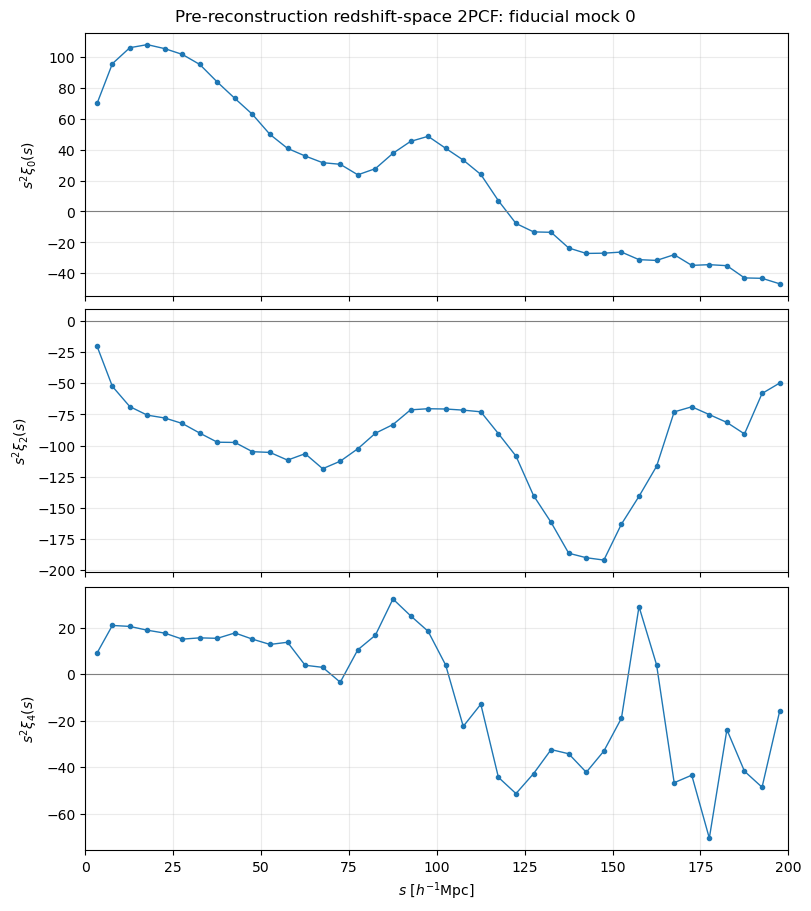

Saved plot: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_xi_rsd.png


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

measurement_file = Path(
    "/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/"
    "fiducial_0_snap003_xi_rsd.npz"
)

with np.load(measurement_file, allow_pickle=False) as data:
    s = data["s"]
    multipoles = [data["xi0"], data["xi2"], data["xi4"]]
    n_halos = int(data["n_halos"])

assert s.shape == (40,)
assert all(values.shape == (40,) for values in multipoles)
assert all(np.isfinite(values).all() for values in multipoles)

print("Loaded:", measurement_file)
print("Halos:", n_halos)
print("Separation range [Mpc/h]:", s.min(), "to", s.max())

fig, axes = plt.subplots(
    3, 1, figsize=(8, 9), sharex=True, constrained_layout=True
)

for ax, ell, values in zip(axes, (0, 2, 4), multipoles):
    ax.plot(s, s**2 * values, "o-", markersize=3, linewidth=1)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_ylabel(fr"$s^2\xi_{{{ell}}}(s)$")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel(r"$s\ [h^{-1}\mathrm{Mpc}]$")
axes[-1].set_xlim(0, 200)
fig.suptitle("Pre-reconstruction redshift-space 2PCF: fiducial mock 0")

plot_file = measurement_file.with_suffix(".png")
fig.savefig(plot_file, dpi=180)
plt.show()

print("Saved plot:", plot_file)

Saved fields: ['s', 'xi0', 'xi2', 'xi4', 's_edges', 'mu_edges', 'n_halos', 'boxsize', 'redshift', 'min_particles']
Halos: 309740
Audit passed: 40 finite bins for each of ell = 0, 2, 4.
First/last measured separations: 3.4119397477530327 197.5209390274295
First/last bin intervals: (np.float64(0.0), np.float64(5.0)) (np.float64(195.0), np.float64(200.0))


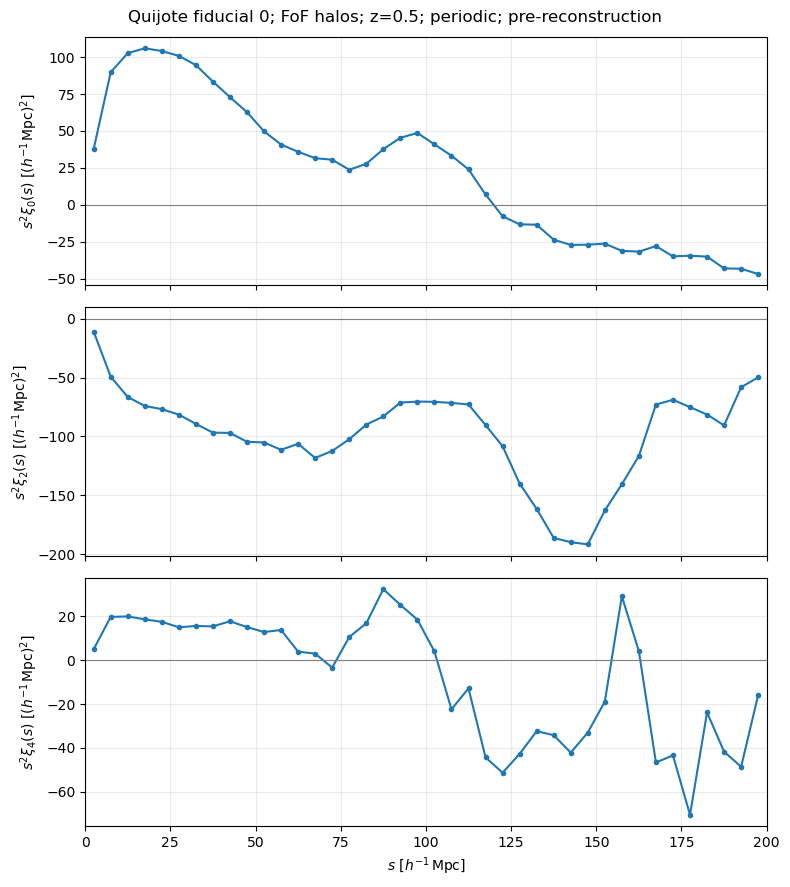

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

path = Path(
    "/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/"
    "fiducial_0_snap003_xi_rsd.npz"
)

with np.load(path, allow_pickle=False) as saved:
    print("Saved fields:", saved.files)

    s = np.asarray(saved["s"])
    xi = np.stack([saved[f"xi{ell}"] for ell in (0, 2, 4)])

    edge_key = next(
        (key for key in ("s_edges", "separation_edges")
         if key in saved.files),
        None,
    )
    if edge_key is None:
        raise KeyError("Separation edges were not saved; inspect the measurement cell.")

    s_edges = np.asarray(saved[edge_key])
    mu_edges = np.asarray(saved["mu_edges"])

    if "n_halos" in saved.files:
        print("Halos:", int(saved["n_halos"]))

assert s.shape == (40,), f"Unexpected separation shape: {s.shape}"
assert xi.shape == (3, 40), f"Unexpected multipole shape: {xi.shape}"
assert np.all(np.isfinite(s)) and np.all(np.isfinite(xi))
assert np.allclose(s_edges, np.arange(0., 205., 5.))
assert np.allclose(mu_edges, np.linspace(-1., 1., 201))
assert np.all((s >= s_edges[:-1]) & (s <= s_edges[1:]))

print("Audit passed: 40 finite bins for each of ell = 0, 2, 4.")
print("First/last measured separations:", s[0], s[-1])
print("First/last bin intervals:",
      (s_edges[0], s_edges[1]),
      (s_edges[-2], s_edges[-1]))

# Use identical horizontal coordinates for every realization later.
s_center = (s_edges[:-1] + s_edges[1:]) / 2

fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
for ax, ell, values in zip(axes, (0, 2, 4), xi):
    ax.plot(s_center, s_center**2 * values, "o-", ms=3)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_ylabel(
        rf"$s^2\xi_{{{ell}}}(s)$ "
        r"$[(h^{-1}\,\mathrm{Mpc})^2]$"
    )
    ax.grid(alpha=0.25)

axes[-1].set_xlabel(r"$s\ [h^{-1}\,\mathrm{Mpc}]$")
axes[-1].set_xlim(0, 200)
fig.suptitle("Quijote fiducial 0; FoF halos; z=0.5; periodic; pre-reconstruction")
fig.tight_layout()
plt.show()

## Test 0 progress: pre-reconstruction 2PCF

### What we have completed

We analysed **Quijote fiducial realization 0**, using the Friends-of-Friends (FoF) halo catalogue from snapshot `003` at \(z=0.5\). The catalogue is in
`/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/0/groups_003/`.

We read the halo positions and velocities using `readfof`, retained halos with at least 20 particles, and placed them in redshift space along the \(z\)-axis. The resulting sample contains **309,740 halos** in a periodic box of side \(1000\,h^{-1}\mathrm{Mpc}\). Its number density is
\(309740/1000^3 = 3.0974\times10^{-4}\,h^3\mathrm{Mpc}^{-3}\).
The position, velocity, and snapshot conventions follow the [Quijote FoF documentation](https://quijote-simulations.readthedocs.io/en/latest/halos.html).

Using `pycorr` with periodic boundaries, we measured the **pre-reconstruction redshift-space 2PCF multipoles** \(\xi_0\), \(\xi_2\), and \(\xi_4\). We used 40 separation bins over \(0\leq s\leq200\,h^{-1}\mathrm{Mpc}\), each \(5\,h^{-1}\mathrm{Mpc}\) wide, and 200 angular bins over \(-1\leq\mu\leq1\). We saved the result to
`/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_0_snap003_xi_rsd.npz`.

We reloaded the saved file and checked its bin edges, array shapes, and finite values. **The archive passed these checks:** each of the three multipoles has 40 finite bins. The first returned separation, \(3.412\,h^{-1}\mathrm{Mpc}\), lies within \([0,5]\); the last, \(197.521\,h^{-1}\mathrm{Mpc}\), lies within \([195,200]\). These returned values represent average separations within their bins. We plotted \(s^2\xi_\ell(s)\) using fixed bin centres so that later realizations can be compared on a common grid; this plotting choice does not change the measured \(\xi_\ell\).

### Interpretation and next step

This is **one pre-reconstruction halo realization**. The plot is a diagnostic, not yet a measurement of BAO significance or a BAO parameter fit.

**Next:** transfer the snapshot `003` FoF catalogue parts for independent fiducial realizations **1–9** into their matching NERSC scratch directories. After checking that every required catalogue part is present, measure all ten realizations with identical settings on a CPU compute node, then plot their mean and mock-to-mock spread. Reconstruction and BAO fitting come later.

In [4]:
from pathlib import Path
Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/1/groups_003").mkdir(
    parents=True, exist_ok=True
)

### Step 4 — Verify realization 1

Globus reported that the snapshot `003` FoF catalogue for fiducial realization 1 transferred successfully. We now check that the catalogue file is present and nonempty in its NERSC scratch directory. This step does not measure the 2PCF yet.

In [5]:
from pathlib import Path

folder = Path(
    "/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/1/groups_003"
)
parts = sorted(folder.glob("group_tab_003.*"))

print("Catalogue directory:", folder)
print("Catalogue parts found:", len(parts))

for part in parts:
    print(part.name, part.stat().st_size, "bytes")

assert parts, "No catalogue parts found at the destination"
assert all(part.stat().st_size > 0 for part in parts), "An empty file was found"
print("Realization 1 file check passed.")

Catalogue directory: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/1/groups_003
Catalogue parts found: 1
group_tab_003.0 26077152 bytes
Realization 1 file check passed.


### Step 5 — Transfer the remaining eight catalogues

Realizations 0 and 1 have been transferred and checked. We will now transfer snapshot `003` from fiducial realizations 2–9. Each realization must go into the NERSC folder with the same number. We will measure their 2PCFs only after all catalogue files are present.

In [11]:
from pathlib import Path

root = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial")

for i in range(2, 10):
    destination = root / str(i) / "groups_003"
    destination.mkdir(parents=True, exist_ok=True)
    print(f"Realization {i}: {destination}")

Realization 2: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/2/groups_003
Realization 3: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/3/groups_003
Realization 4: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/4/groups_003
Realization 5: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/5/groups_003
Realization 6: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/6/groups_003
Realization 7: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/7/groups_003
Realization 8: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/8/groups_003
Realization 9: /pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial/9/groups_003


### Step 6 — Check all ten transferred catalogues

We check that realizations 0–9 each have at least one nonempty snapshot `003` FoF catalogue part in the correct NERSC folder. This checks file presence and size; we will check that `readfof` can read each catalogue during the measurement step.

### Step 7 — Verify the ten selected FoF catalogues

We check that each selected fiducial realization has a nonempty snapshot `003` catalogue in its own NERSC scratch folder. This is a file-transfer check; reading and measuring the catalogues comes next.

In [34]:
from pathlib import Path

root = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial")
ids = (0, 1, 10, 100, 1000, 10000, 10001, 10002, 10003, 10004)

ready = 0
for i in ids:
    expected = root / str(i) / "groups_003" / "group_tab_003.0"
    one_level_high = root / str(i) / "group_tab_003.0"

    if expected.is_file() and expected.stat().st_size > 0:
        ready += 1
        print(f"{i}: READY — {expected.stat().st_size:,} bytes")
    elif one_level_high.is_file():
        print(f"{i}: ONE FOLDER TOO HIGH — {one_level_high}")
    else:
        print(f"{i}: MISSING from expected location")

print(f"\nReady: {ready}/10")

0: READY — 26,018,184 bytes
1: READY — 26,077,152 bytes
10: READY — 25,961,148 bytes
100: READY — 25,954,512 bytes
1000: READY — 25,926,120 bytes
10000: READY — 26,043,132 bytes
10001: READY — 25,949,808 bytes
10002: READY — 23,068,672 bytes
10003: READY — 26,060,352 bytes
10004: READY — 25,940,232 bytes

Ready: 10/10


In [36]:
from pathlib import Path
import struct

root = Path("/pscratch/sd/m/mawais/Quijote/Halos/FoF/fiducial")
ids = (0, 1, 10, 100, 1000, 10000, 10001, 10002, 10003, 10004)

passed = 0

for i in ids:
    file = root / str(i) / "groups_003" / "group_tab_003.0"

    if not file.is_file():
        print(f"{i}: MISSING")
        continue

    actual = file.stat().st_size
    with file.open("rb") as f:
        header = f.read(24)

    if len(header) != 24:
        print(f"{i}: INCOMPLETE HEADER — {actual:,} bytes")
        continue

    n_groups, total_groups, n_ids, total_ids, n_files = struct.unpack(
        "<iiiQI", header
    )
    expected = 24 + 84 * n_groups

    if n_files != 1 or n_groups != total_groups:
        status = "CHECK PARTS/HEADER"
    elif actual == expected:
        status = "COMPLETE"
        passed += 1
    elif actual < expected:
        status = "INCOMPLETE UPLOAD"
    else:
        status = "UNEXPECTED SIZE"

    print(
        f"{i}: {status} | halos={n_groups:,} | "
        f"actual={actual:,} | expected={expected:,} bytes | parts={n_files}"
    )

print(f"\nComplete single-part catalogues: {passed}/10")

0: COMPLETE | halos=309,740 | actual=26,018,184 | expected=26,018,184 bytes | parts=1
1: COMPLETE | halos=310,442 | actual=26,077,152 | expected=26,077,152 bytes | parts=1
10: COMPLETE | halos=309,061 | actual=25,961,148 | expected=25,961,148 bytes | parts=1
100: COMPLETE | halos=308,982 | actual=25,954,512 | expected=25,954,512 bytes | parts=1
1000: COMPLETE | halos=308,644 | actual=25,926,120 | expected=25,926,120 bytes | parts=1
10000: COMPLETE | halos=310,037 | actual=26,043,132 | expected=26,043,132 bytes | parts=1
10001: COMPLETE | halos=308,926 | actual=25,949,808 | expected=25,949,808 bytes | parts=1
10002: COMPLETE | halos=308,529 | actual=25,916,460 | expected=25,916,460 bytes | parts=1
10003: COMPLETE | halos=310,242 | actual=26,060,352 | expected=26,060,352 bytes | parts=1
10004: COMPLETE | halos=308,812 | actual=25,940,232 | expected=25,940,232 bytes | parts=1

Complete single-part catalogues: 10/10
